<a href="https://colab.research.google.com/github/khairulhawani/AIOT-platform/blob/main/Green-Tourism-Economic-Growth-Indonesia-Taiwan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**# CELL 1 — LIBRARY INSTALLATION**

In [1]:
!pip install xgboost shap optuna statsmodels -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 13.6 MB/s eta 0:00:00


# **CELL 2 — IMPORT LIBRARY & SETUP**

In [2]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

# --- Create an output folder to save all the analyzed images ---
OUTPUT_DIR = '/content/output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- Dataset path (adjust if uploading manually, or mounting Google Drive) ---
DATASET_PATH = '/content/drive/MyDrive/PNB/Bisnis Digital/2025-2026 Genap/Penelitian/DIPA International 2026/Laporan/ML_Modeling/Research_Dataset.xlsx'
RANDOM_STATE = 42

print("✓ Environment ready")
print(f"✓ The output will be saved in: {OUTPUT_DIR}")

✓ Environment ready
✓ The output will be saved in: /content/output


# **CELL 3 — IMPORT ALL RESEARCH MODULES**

In [9]:
import sys

sys.path.append("/content/drive/MyDrive/PNB/Bisnis Digital/2025-2026 Genap/Penelitian/DIPA International 2026/Laporan/ML_Modeling")

In [10]:
import modul_01_preprocessing
import modul_02_metadata
import modul_03_eda_feature_selection
import modul_04_baseline_model
import modul_05_hyperparameter_tuning
import modul_06_shap_analysis
import modul_07_evaluation

In [11]:
from modul_01_preprocessing import run_preprocessing
from modul_02_metadata import (
    generate_metadata, generate_descriptive_stats,
    generate_source_summary, generate_imputation_notes,
    print_full_documentation
)
from modul_03_eda_feature_selection import run_eda_feature_selection
from modul_04_baseline_model import run_baseline_model
from modul_05_hyperparameter_tuning import (
    run_gridsearch_tuning, run_optuna_tuning, compare_baseline_vs_tuned
)
from modul_06_shap_analysis import run_shap_analysis
from modul_07_evaluation import run_full_evaluation

print("✓ All modules imported successfully")

✓ All modules imported successfully


# **CELL 4 — STAGE 1: PREPROCESSING and FEATURE ENGINEERING**

In [17]:
DATASET_PATH = "/content/drive/MyDrive/PNB/Bisnis Digital/2025-2026 Genap/Penelitian/DIPA International 2026/Laporan/ML_Modeling/Research_Dataset.xlsx"

In [19]:
DATASET_PATH = "/content/Research_Dataset.xlsx"

In [20]:
print("\n" + "#" * 70)
print("#  TAHAP 1: PREPROCESSING & FEATURE ENGINEERING")
print("#" * 70)

df, missing_report = run_preprocessing(
    filepath=DATASET_PATH,
    sheet_name='Research_Dataset',
    save_csv=f'{OUTPUT_DIR}/Research_Dataset_Preprocessing.csv'
)

print("\nPreview the first 5 rows of the preprocessed dataset:")
display(df.head())


######################################################################
#  TAHAP 1: PREPROCESSING & FEATURE ENGINEERING
######################################################################
  1. DATA LOADING & STRUCTURE CLEANING
✓ Dataset loaded: 32 rows x 48 columns
✓ Countries: ['IDN', 'TWN']
✓ Year range: 2007–2022
✓ Data types converted (44 numeric columns)

  2. MISSING VALUES AUDIT
✓ No missing values were found in the dataset.

  3. OUTLIER DETECTION (IQR Method, per Country)
Total rows flagged as outliers: 12 out of 32 rows

Details of 40 outlier events (top 15):
country  year                                   column        value   lower_bound  upper_bound
    IDN  2019                   tourist_arrivals_water 4.160600e+06  8.511875e+05 3.740688e+06
    IDN  2021                   tourist_arrivals_water 4.155000e+05  8.511875e+05 3.740688e+06
    IDN  2018                    tourist_arrivals_land 2.968300e+06 -1.499700e+06 2.631500e+06
    IDN  2020           tourism_expenditu

,country,country_name,year,period_category,tourist_arrivals_total,tourist_arrivals_air,tourist_arrivals_water,tourist_arrivals_land,tourist_arrivals_other,tourism_receipts_usd,tourism_expenditure_abroad_usd,inbound_accommodation_total_guests,inbound_accommodation_total_overnights,inbound_accommodation_hotels_guests,domestic_trips_total,tourist_departures_total,hotel_establishments,hotel_occupancy_rate_rooms_pct,tourism_employment_thousand,domestic_trips_overnight_visitors,domestic_trips_sameday_visitors,domestic_accommodation_total_guests,domestic_accommodation_hotels_guests,outbound_departures_total,outbound_departures_overnight_visitors,outbound_departures_sameday_visitors,outbound_tourism_expenditure_total_musd,outbound_tourism_expenditure_travel_musd,outbound_tourism_expenditure_transport_musd,accommodation_establishments_count,accommodation_rooms_count,accommodation_bedplaces_count,accommodation_occupancy_rate_rooms_pct,accommodation_occupancy_rate_bedplaces_pct,accommodation_avg_length_of_stay_nights,tourism_employment_total,tourism_employment_accommodation_hotels,tourism_employment_other_accommodation,tourism_employment_food_beverage,tourism_employment_passenger_transport,tourism_employment_travel_agencies,tourism_employment_other_tourism_industries,gdp_growth_annual_pct,renewable_energy_pct_tfec,co2_total_mt,co2_agri_sector_mt,co2_per_gdp_intensity,co2_per_capita_t,outlier_flag,receipts_per_arrival_usd,co2_per_tourism_receipt,arrivals_yoy_growth_pct,receipts_yoy_growth_pct,co2_yoy_change_pct,green_tourism_index,tourism_sustainability_index,eco_efficiency_index,tourist_arrivals_total_scaled,tourism_receipts_usd_scaled,gdp_growth_annual_pct_scaled,co2_total_mt_scaled,renewable_energy_pct_tfec_scaled
0,IDN,Indonesia,2007,pre_covid,5506000.0,3304000.0,2163000.0,39000.0,1046559.0,5.831000e+09,6.578000e+09,5273000.0,0.0,4298000.0,222389000.0,5158000.0,13584.0,46.89,199.6,354353000.0,367806000.0,37672000.0,13113000.0,5158000.0,503000.0,1208000.0,6578.0,4904.0,1674.0,13584.0,317824.0,516919.0,46.89,57.23,2.08,199600.0,113200.0,86400.0,209800.0,21400.0,90100.0,2191200.0,6.345022,40.0,401.793433,4.532523,0.217224,1.724517,False,1059.026517,0.068906,NaN,NaN,NaN,5.804973e+06,0.748696,0.015792,0.271384,0.295850,1.000000,0.013944,0.948357
1,IDN,Indonesia,2008,pre_covid,6234000.0,4091000.0,2095000.0,48000.0,1046559.0,8.150000e+09,8.801000e+09,5273000.0,0.0,4805000.0,225041000.0,5486000.0,13751.0,48.06,247.6,354353000.0,367806000.0,38544000.0,14351000.0,5486000.0,503000.0,1208000.0,8801.0,5554.0,3247.0,13751.0,325218.0,523940.0,48.06,57.23,2.03,247600.0,137600.0,110000.0,209800.0,21400.0,90100.0,2191200.0,6.013704,41.1,397.255368,4.798095,0.202588,1.682152,False,1307.346808,0.048743,13.221940,39.770194,-1.129452,8.431982e+06,0.802368,0.015138,0.321420,0.425715,0.960607,0.000000,1.000000
2,IDN,Indonesia,2009,pre_covid,6324000.0,4396000.0,1874000.0,54000.0,1010723.0,6.053000e+09,6.908000e+09,5273000.0,0.0,5359000.0,229730000.0,5053000.0,13932.0,48.31,249.7,354353000.0,367806000.0,42980000.0,17213000.0,5053000.0,503000.0,1208000.0,6908.0,5316.0,1592.0,13932.0,334817.0,519205.0,48.31,55.83,1.95,249700.0,140900.0,108800.0,209800.0,21400.0,90100.0,2191200.0,4.628871,38.2,411.349075,5.895685,0.200495,1.718681,False,957.147375,0.067958,1.443696,-25.730061,3.547770,5.621128e+06,0.739494,0.011253,0.327606,0.308282,0.795952,0.043306,0.863850
3,IDN,Indonesia,2010,pre_covid,7003000.0,4998000.0,1955000.0,50000.0,427521.0,7.618000e+09,8.432000e+09,5273000.0,0.0,5589000.0,234377000.0,6235000.0,14587.0,48.86,261.2,354353000.0,367806000.0,46586000.0,18560000.0,6235000.0,503000.0,1208000.0,8432.0,6395.0,2037.0,14587.0,353138.0,542640.0,48.86,58.63,1.93,261200.0,149700.0,111500.0,209800.0,21400.0,90100.0,2191200.0,6.223854,36.0,443.682042,5.393456,0.203583,1.829436,False,1087.819506,0.058241,10.736875,25.854948,7.860226,6.181183e+06,0.751132,0.014028,0.374274,0.395923,0.985593,0.142656,0.760563
4,IDN,Indonesia,2011,pre_covid,7650000.0,5446000.0,2148000.0

# **CELL 5 — STAGE 2: VARIABLE METADATA DOCUMENTATION**

In [22]:
print("\n" + "#" * 70)
print("#  STAGE 2: VARIABLE METADATA DOCUMENTATION")
print("#" * 70)

df_metadata = print_full_documentation(df)

# Save metadata to Excel for report/article appendix
with pd.ExcelWriter(f'{OUTPUT_DIR}/Metadata_Variabel.xlsx', engine='openpyxl') as writer:
    df_metadata.to_excel(writer, sheet_name='Metadata Variabel', index=False)
    generate_descriptive_stats(df).to_excel(writer, sheet_name='Statistik Deskriptif')
    generate_source_summary().to_excel(writer, sheet_name='Sumber Data', index=False)
    generate_imputation_notes().to_excel(writer, sheet_name='Catatan Imputasi', index=False)

print(f"\n✓ Complete metadata saved: {OUTPUT_DIR}/Metadata_Variabel.xlsx")


######################################################################
#  STAGE 2: VARIABLE METADATA DOCUMENTATION
######################################################################
  VARIABLE METADATA
 no                               variable_name               variable_group             model_role
  1                                     country        Identification & Time             Identifier
  2                                country_name        Identification & Time             Identifier
  3                                        year        Identification & Time             Time Index
  4                             period_category        Identification & Time    Categorical Feature
  5                      tourist_arrivals_total     Inbound Tourism Arrivals       Main Feature (X)
  6                        tourist_arrivals_air     Inbound Tourism Arrivals Supporting Feature (X)
  7                      tourist_arrivals_water     Inbound Tourism Arrivals Supporting Featu

# **CELL 6 — STAGE 2a: EDA & FEATURE SELECTION**


######################################################################
#  STAGE 2a: EDA & FEATURE SELECTION
######################################################################
Total numeric feature candidates (after excluding identifiers and redundants): 46
List: ['tourist_arrivals_total', 'tourist_arrivals_air', 'tourist_arrivals_water', 'tourist_arrivals_land', 'tourist_arrivals_other', 'tourism_receipts_usd', 'tourism_expenditure_abroad_usd', 'inbound_accommodation_total_guests', 'inbound_accommodation_total_overnights', 'inbound_accommodation_hotels_guests', 'domestic_trips_total', 'tourist_departures_total', 'hotel_establishments', 'hotel_occupancy_rate_rooms_pct', 'domestic_trips_overnight_visitors', 'domestic_trips_sameday_visitors', 'domestic_accommodation_total_guests', 'domestic_accommodation_hotels_guests', 'outbound_departures_overnight_visitors', 'outbound_departures_sameday_visitors', 'outbound_tourism_expenditure_travel_musd', 'outbound_tourism_expenditure_transport_

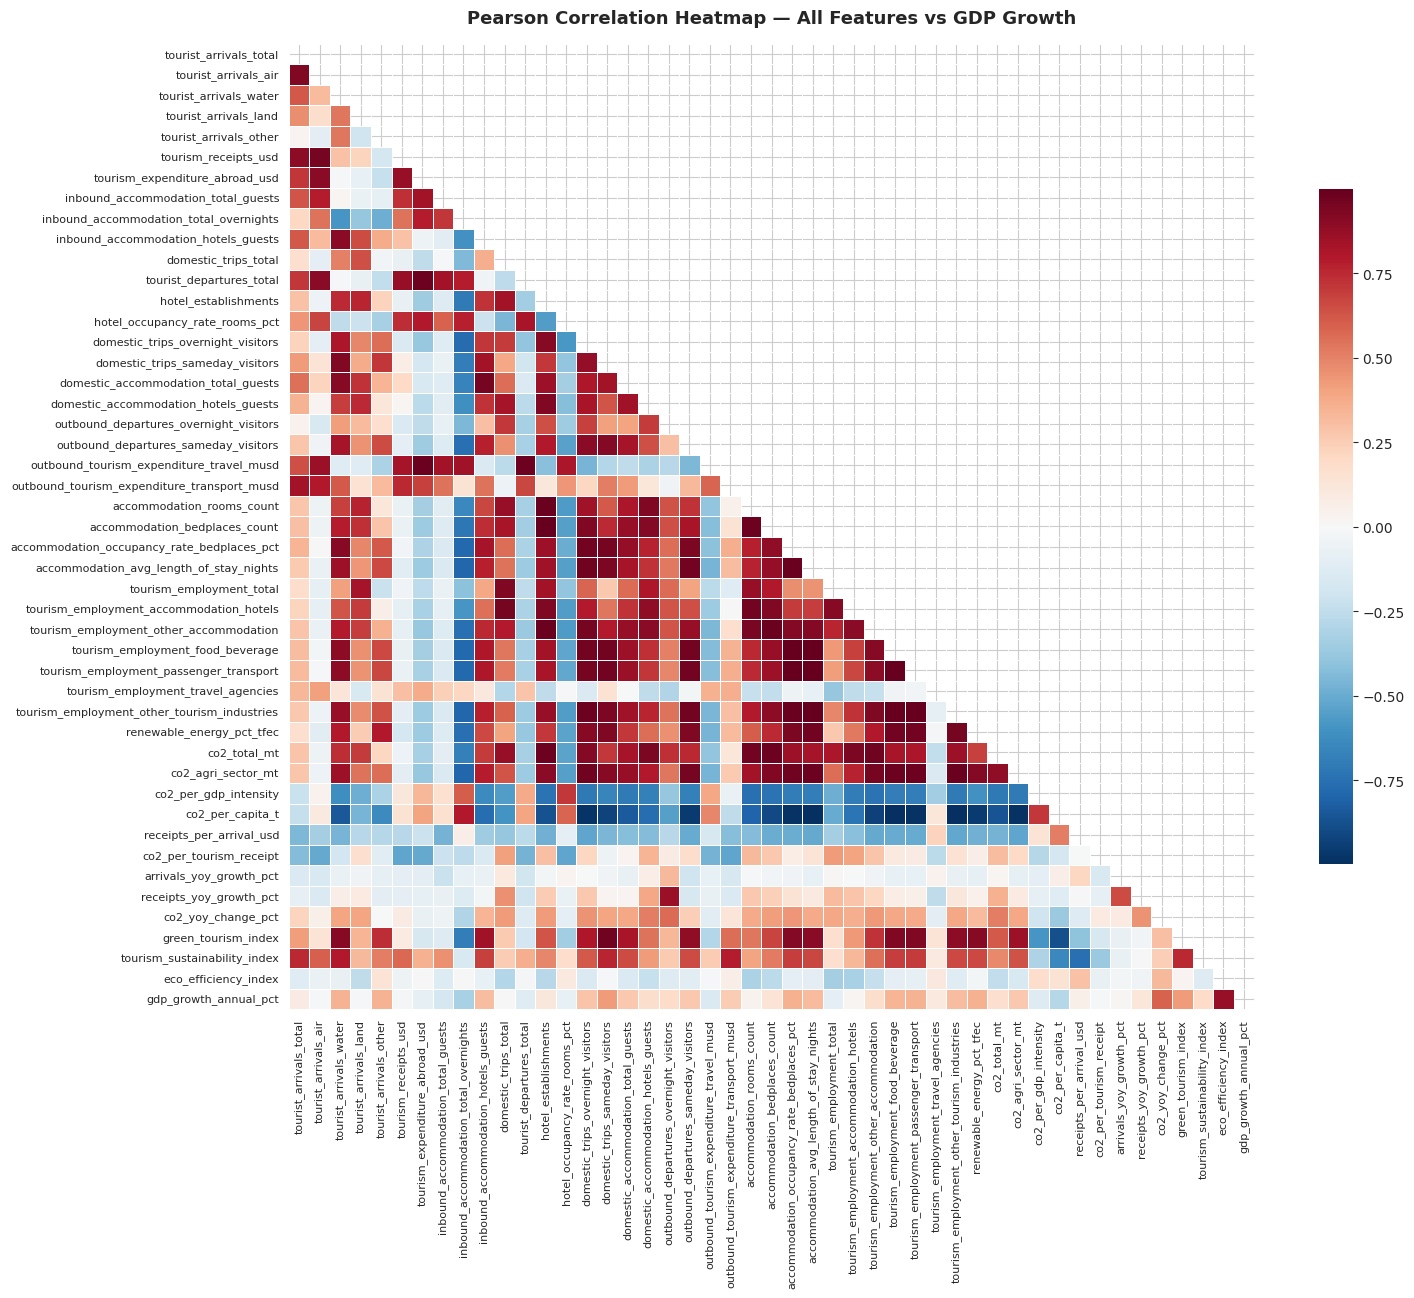


Top 15 features with the highest absolute correlation to 'gdp_growth_annual_pct':
eco_efficiency_index                           0.8707
co2_yoy_change_pct                             0.5904
domestic_trips_sameday_visitors                0.4242
green_tourism_index                            0.4242
renewable_energy_pct_tfec                      0.3574
accommodation_occupancy_rate_bedplaces_pct     0.3567
tourist_arrivals_water                         0.3517
tourist_arrivals_other                         0.3515
tourism_employment_passenger_transport         0.3473
tourism_employment_food_beverage               0.3396
inbound_accommodation_total_overnights        -0.3203
accommodation_avg_length_of_stay_nights        0.3175
tourism_employment_other_tourism_industries    0.3116
inbound_accommodation_hotels_guests            0.3113
domestic_trips_overnight_visitors              0.2849

  2a.2 COUNTRY-LEVEL DISTRIBUTION
✓ Distribution plot saved: /content/output/distribution_by_country.png


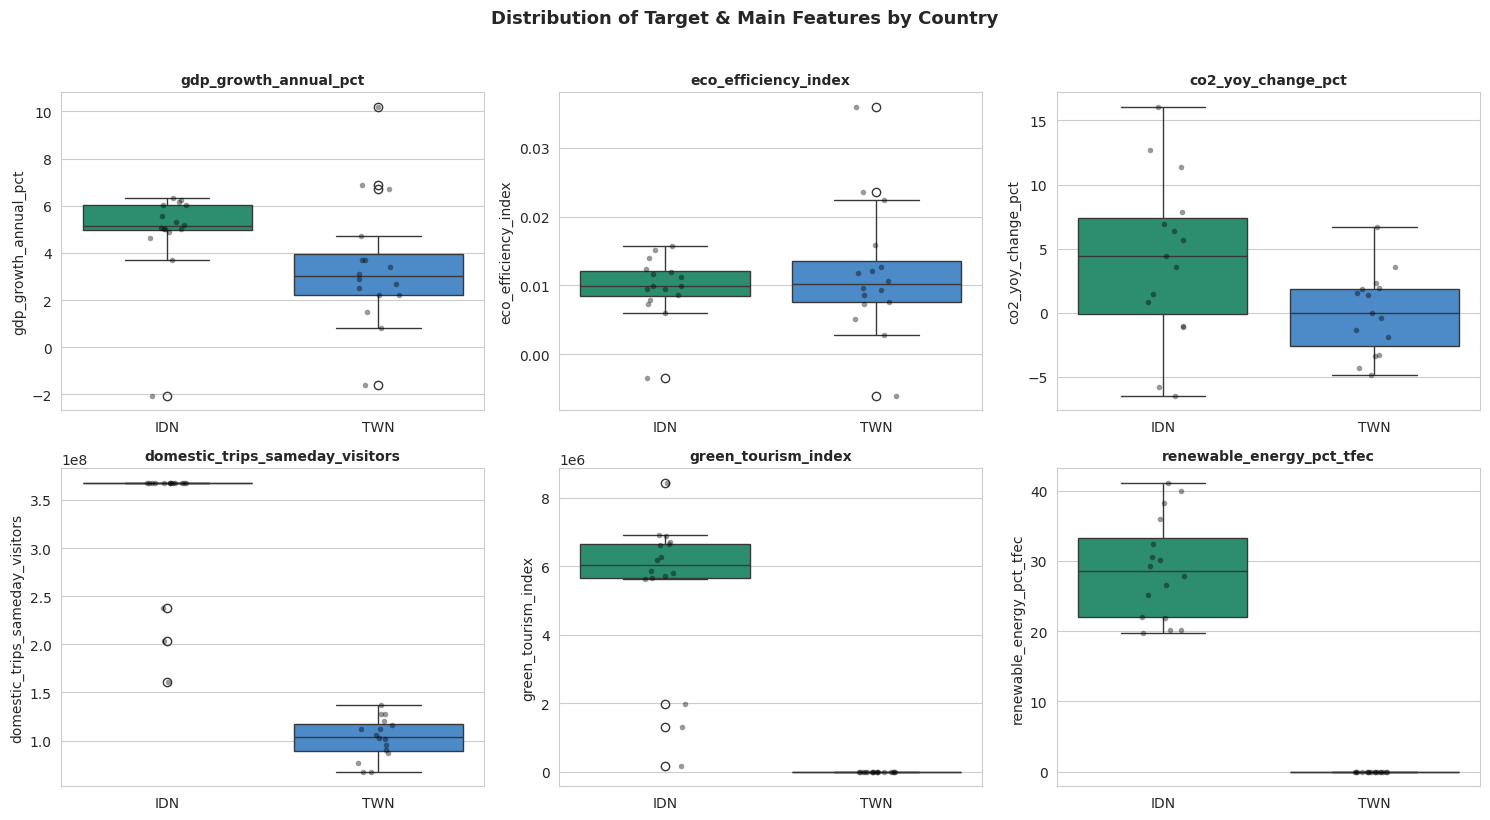


Features visualized: ['gdp_growth_annual_pct', 'eco_efficiency_index', 'co2_yoy_change_pct', 'domestic_trips_sameday_visitors', 'green_tourism_index', 'renewable_energy_pct_tfec']

Mean summary by country:
         gdp_growth_annual_pct  eco_efficiency_index  co2_yoy_change_pct  domestic_trips_sameday_visitors  green_tourism_index  renewable_energy_pct_tfec
country                                                                                                                                                  
IDN                     4.8808                0.0098              4.1771                      336439125.0         5.419666e+06                    28.8375
TWN                     3.4750                0.0118             -0.0111                      103033812.5         0.000000e+00                     0.0000

  2a.3 SELECTKBEST (k=10, f_regression score)
Rows valid for SelectKBest (after dropping NaN): 30 of 32
                                    feature   f_score      p_value  sele

In [27]:
print("\n" + "#" * 70)
print("#  STAGE 2a: EDA & FEATURE SELECTION")
print("#" * 70)

TARGET = 'gdp_growth_annual_pct'

fitur_final, laporan_eda = run_eda_feature_selection(
    df=df,
    target=TARGET,
    k_selectkbest=10,
    n_features_final=8,
    vif_threshold=10.0,
    save_dir=OUTPUT_DIR
)

print(f"\n{'='*70}")
print(f"FINAL FEATURES USED FOR MODELING ({len(fitur_final)} features):")
print(f"{'='*70}")
for i, f in enumerate(fitur_final, 1):
    print(f"  {i}. {f}")

# **CELL 7 — STAGE 2b: SPLIT DATA & BASELINE MODEL XGBOOST**

In [29]:
print("\n" + "#" * 70)
print("#  STAGE 2b: SPLIT DATA & BASELINE MODEL XGBOOST")
print("#" * 70)

model_baseline, X_train, X_test, y_train, y_test, baseline_metrics = run_baseline_model(
    df=df,
    column_features=fitur_final,
    target=TARGET,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# Additional info (country, year) for interpretation in the next stage
info_train = df.loc[X_train.index, ['country', 'year']]
info_test  = df.loc[X_test.index, ['country', 'year']]


######################################################################
#  STAGE 2b: SPLIT DATA & BASELINE MODEL XGBOOST
######################################################################
  DATA PREPARATION FOR MODELING
Rows available for modeling: 32
Number of features: 8

Note: the following features have missing values (handled natively by XGBoost):
co2_yoy_change_pct    2

Country distribution:
country
IDN    16
TWN    16

  DATA SPLIT (Train 80% / Test 20%, stratified by country)
Train set : 25 rows (78.1%)
Test set  : 7 rows (21.9%)

Country distribution — Train set:
country
TWN    13
IDN    12

Country distribution — Test set:
country
IDN    4
TWN    3

  BASELINE MODEL — XGBRegressor (Default Parameters)
✓ Baseline model trained successfully
  Default parameters: n_estimators=None, max_depth=None, learning_rate=None

  BASELINE EVALUATION
         RMSE      R2     MAE
train  0.0006  1.0000  0.0004
test   1.3944  0.2462  0.9770

Gap R² (train - test): 0.7538  ⚠ A fairly larg

# **CELL 8 — STAGE 2c: HYPERPARAMETER TUNING**

In [30]:
print("\n" + "#" * 70)
print("#  STAGE 2c: HYPERPARAMETER TUNING")
print("#" * 70)

# ---------------------------------------------------------------------------
# TUNING METHOD OPTIONS — choose one (or run both for comparison).
# GridSearchCV is suitable for this small dataset because it is exhaustive
# and the results are reproducible; Optuna is more efficient if you want
# to expand the search space significantly.
# ---------------------------------------------------------------------------

# --- OPTION A: GridSearchCV (default, recommended for N~30 rows) ---
PARAM_GRID = {
    'n_estimators':     [50, 100, 200, 300],
    'max_depth':        [2, 3, 4, 5],
    'learning_rate':    [0.01, 0.05, 0.1, 0.2],
    'subsample':        [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
}

model_tuned, best_params, cv_results = run_gridsearch_tuning(
    X_train, y_train,
    param_grid=PARAM_GRID,
    cv=5,
    random_state=RANDOM_STATE
)

# --- OPTION B: Optuna (enable by uncommenting below) ---
# model_tuned, best_params, study = run_optuna_tuning(
#     X_train, y_train, n_trials=100, cv=5, random_state=RANDOM_STATE
# )
# from modul_05_hyperparameter_tuning import plot_optuna_history
# plot_optuna_history(study)   # visualisasi riwayat optimisasi (butuh plotly)

# --- Baseline vs tuned performance comparison ---
df_perbandingan_tuning = compare_baseline_vs_tuned(
    baseline_metrics, model_tuned, X_train, X_test, y_train, y_test
)


######################################################################
#  STAGE 2c: HYPERPARAMETER TUNING
######################################################################
  GRIDSEARCHCV — HYPERPARAMETER TUNING XGBOOST
Parameter grid: {'n_estimators': [50, 100, 200, 300], 'max_depth': [2, 3, 4, 5], 'learning_rate': [0.01, 0.05, 0.1, 0.2], 'subsample': [0.6, 0.8, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0]}
Total combinations: 576 x cv=5 folds = 2880 fits
Fitting 5 folds for each of 576 candidates, totalling 2880 fits

✓ Tuning completed
Best RMSE (CV, sign reversed): 1.0361
Best parameters:
  colsample_bytree: 1.0
  learning_rate: 0.05
  max_depth: 4
  n_estimators: 300
  subsample: 1.0

Top 5 best combinations:
                                                                                                    params  mean_test_score  std_test_score  rank_test_score
0  {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300, 'subsample': 1.0}        -1.

# **CELL 9 — STAGE 2d: SHAP INTERPRETABILITY ANALYSIS**


######################################################################
#  STAGE 2d: SHAP INTERPRETABILITY ANALYSIS
######################################################################
  INITIALIZING SHAP TREEEXPLAINER
✓ TreeExplainer created successfully for the XGBoost model

  2d.1 GLOBAL IMPORTANCE — BEESWARM PLOT
✓ Beeswarm plot saved: /content/output/shap_beeswarm.png


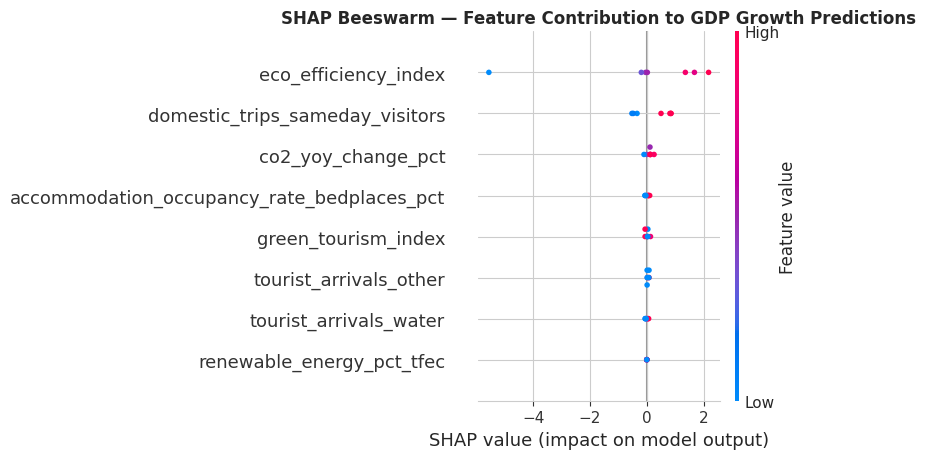


Feature ranking based on mean(|SHAP value|):
                                   feature  mean_abs_shap
                      eco_efficiency_index         1.5760
           domestic_trips_sameday_visitors         0.6230
                        co2_yoy_change_pct         0.1200
accommodation_occupancy_rate_bedplaces_pct         0.0593
                       green_tourism_index         0.0514
                    tourist_arrivals_other         0.0425
                    tourist_arrivals_water         0.0406
                 renewable_energy_pct_tfec         0.0019

  2d.3 EXPLANATION OF EXTREME CASES (Highest & Lowest Predictions)

--- HIGHEST PREDICTION (index=5) ---
Observation: IDN - Year 2010
Model prediction: 6.1369
Actual value    : 6.2239

  2d.2 LOCAL EXPLANATION — WATERFALL PLOT (index=5)
Observation: IDN - Year 2010


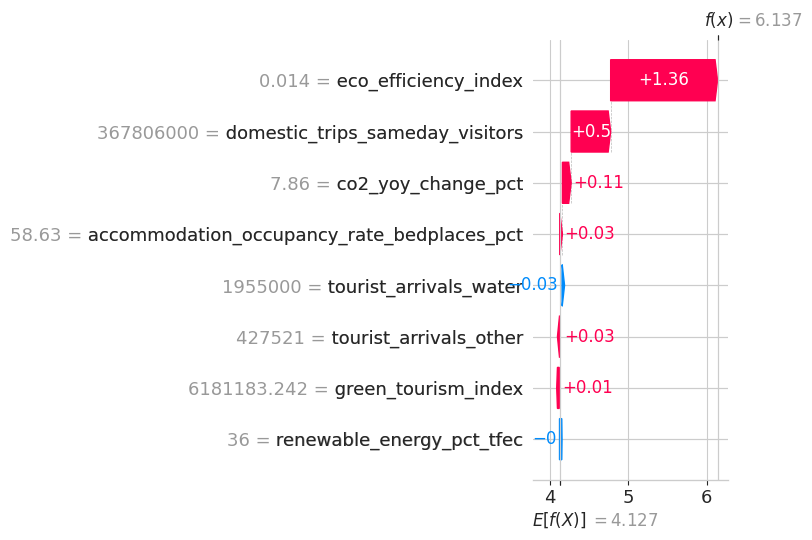


--- LOWEST PREDICTION (index=3) ---
Observation: TWN - Year 2008
Model prediction: -1.8853
Actual value    : 0.8000

  2d.2 LOCAL EXPLANATION — WATERFALL PLOT (index=3)
Observation: TWN - Year 2008


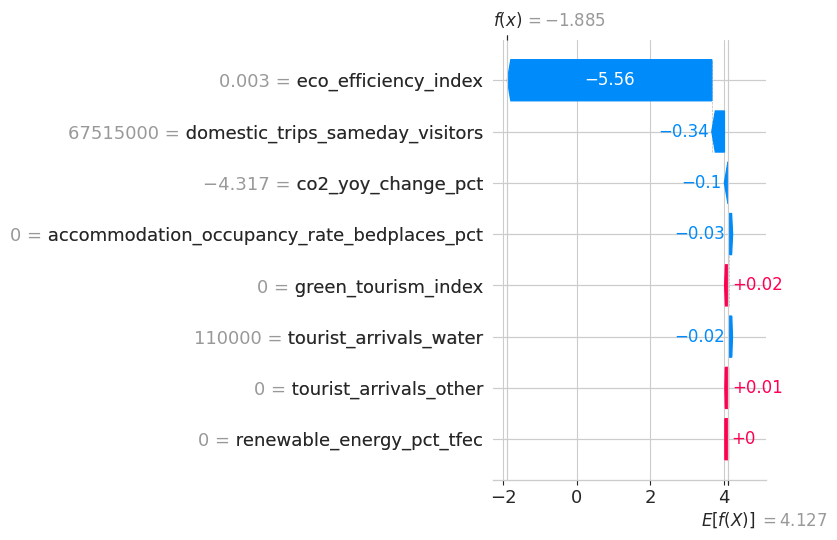


  2d.4 DEPENDENCE PLOT — 4 Key Features

> eco_efficiency_index


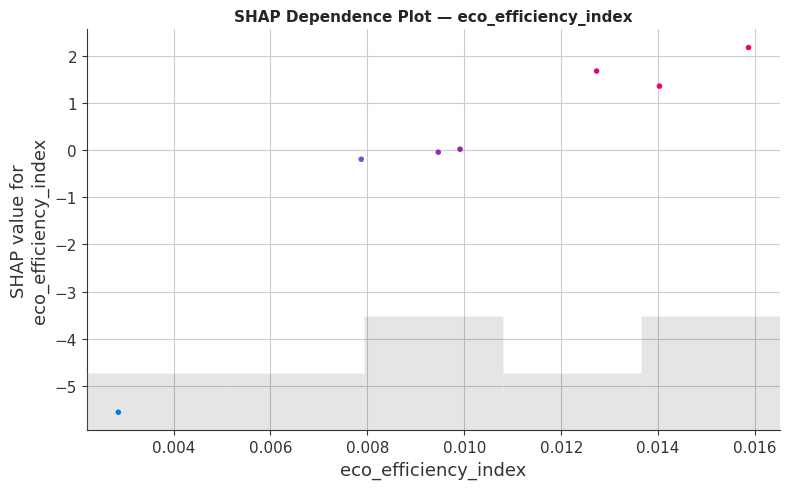


> domestic_trips_sameday_visitors


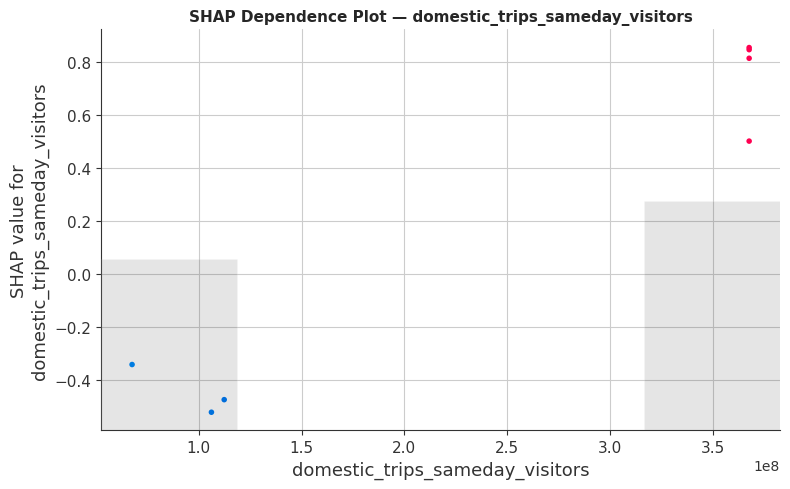


> co2_yoy_change_pct


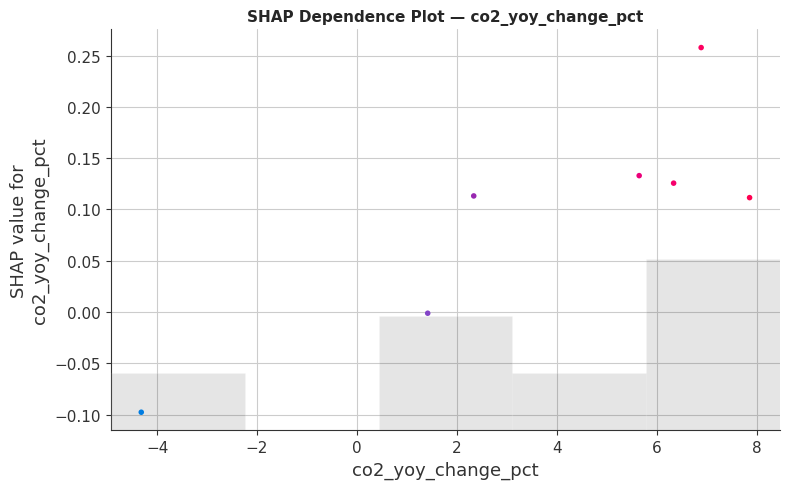


> accommodation_occupancy_rate_bedplaces_pct


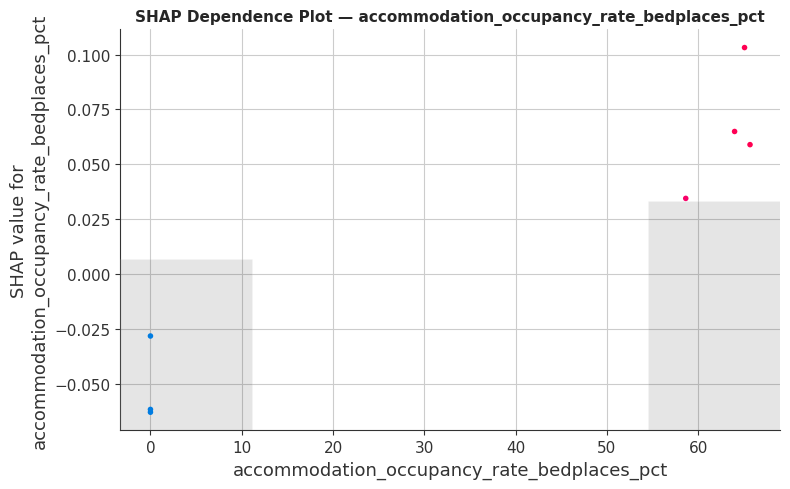


  DRAFT SHAP RESULT NARRATIVE (for the Results & Discussion section)
SHAP-based interpretability analysis identifies eco_efficiency_index, domestic_trips_sameday_visitors, co2_yoy_change_pct, accommodation_occupancy_rate_bedplaces_pct, and green_tourism_index as the most influential predictors of sustainable economic growth in the XGBoost model, ranked by mean absolute SHAP value. The feature 'eco_efficiency_index' exhibits the highest contribution (mean |SHAP| = 1.5760), indicating its dominant role in shaping the model's predictions across both Indonesia and Taiwan. This finding is consistent with the theoretical expectation that tourism-driven economic indicators interact non-linearly with environmental sustainability metrics, supporting the Ecological Modernization Theory framework adopted in this study.


In [32]:
print("\n" + "#" * 70)
print("#  STAGE 2d: SHAP INTERPRETABILITY ANALYSIS")
print("#" * 70)

shap_values, explainer, mean_abs_shap, shap_narrative = run_shap_analysis(
    model=model_tuned,
    X_train=X_train,
    X_test=X_test,
    y_test=y_test,
    additional_info=info_test,
    n_dependence_features=4,
    save_dir=OUTPUT_DIR
)

# **CELL 10 — STAGE 2e: MODEL EVALUATION & COMPARATIVE ANALYSIS**


######################################################################
#  STAGE 2e: MODEL EVALUATION & COMPARATIVE ANALYSIS
######################################################################
  1. MAIN EVALUATION METRICS (RMSE, R², MAE)
         RMSE      R2     MAE
Train  0.0017  1.0000  0.0012
Test   1.2671  0.3775  0.8834

Interpretation of R² (test): the model explains 37.75% of the variation in GDP growth in the test data.

  2. RESIDUAL PLOT
✓ Residual plot saved: /content/output/residual_plot.png


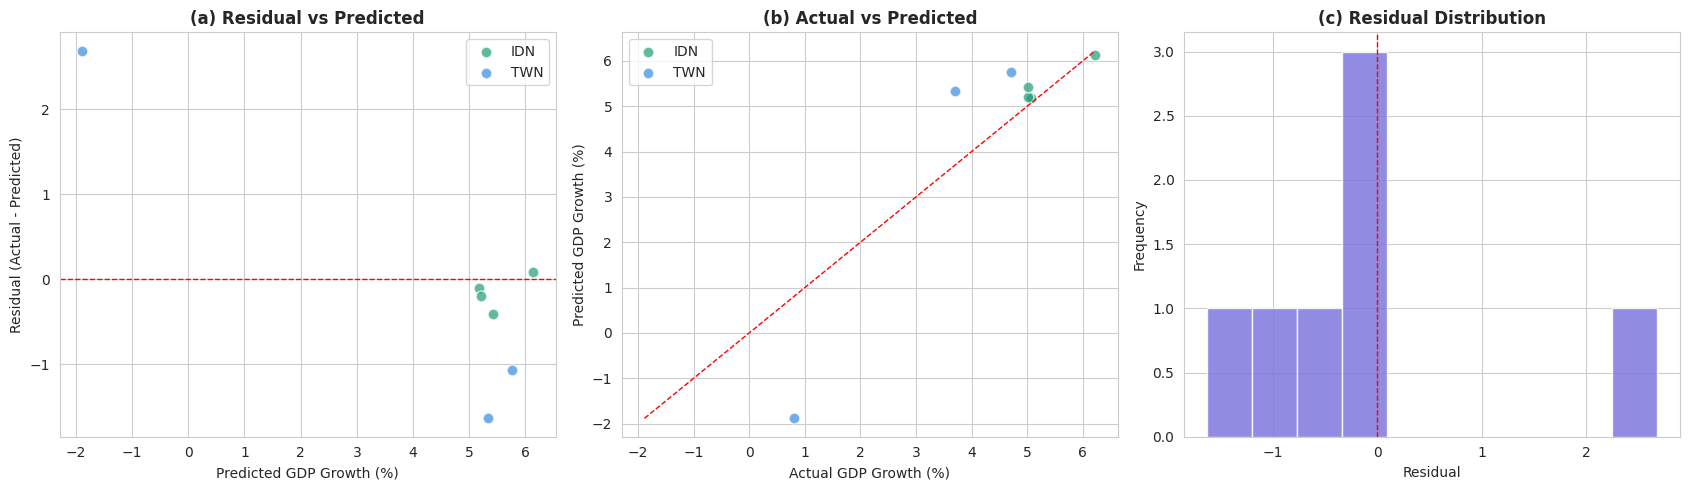


Residual statistics: mean=-0.0914, std=1.2638
Note: ideal residuals are randomly scattered around 0 without a systematic pattern.

  3. PREDICTION COMPARISON: INDONESIA vs TAIWAN
       RMSE      R2     MAE
IDN  0.2367  0.7901  0.2001
TWN  1.9162 -0.3422  1.7946

Prediction details per observation:
country  year   actual  predicted  residual
    IDN  2010 6.223854   6.136883  0.086971
    IDN  2014 5.006668   5.206213 -0.199545
    IDN  2017 5.069786   5.176953 -0.107167
    IDN  2019 5.019288   5.425826 -0.406538
    TWN  2008 0.800000  -1.885272  2.685272
    TWN  2011 3.700000   5.334910 -1.634910
    TWN  2014 4.700000   5.763689 -1.063689
✓ Comparison plot saved: /content/output/comparison_countries.png


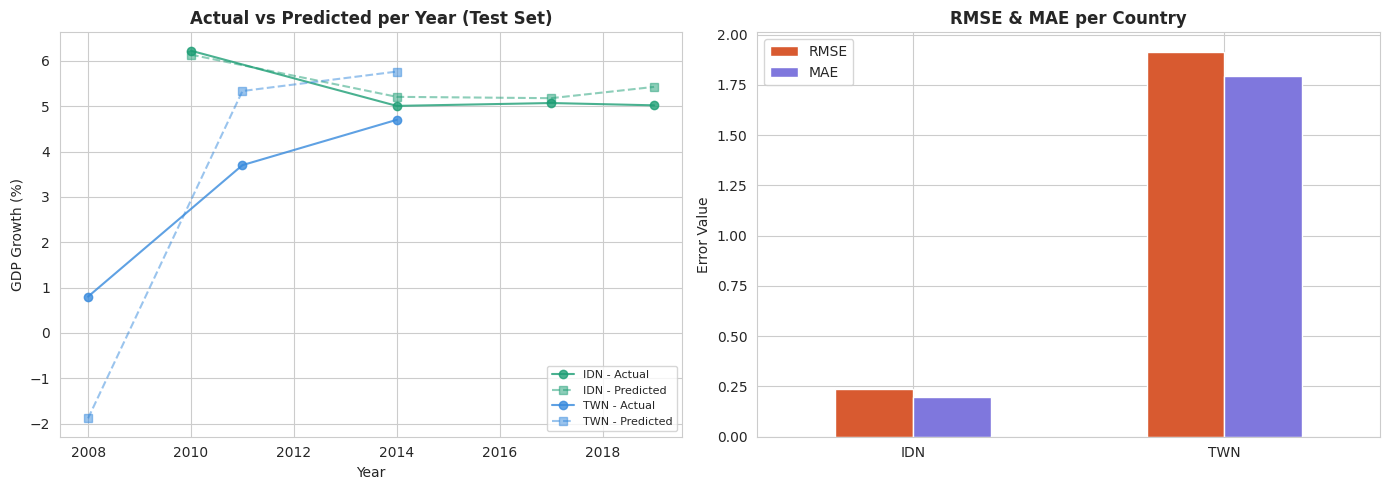


  4. K-FOLD CROSS-VALIDATION (k=5)
          RMSE     MAE      R2
Fold-1  0.3420  0.2932  0.9237
Fold-2  1.3560  0.7068  0.8518
Fold-3  1.4211  0.9975  0.7160
Fold-4  1.0368  0.8524  0.6358
Fold-5  1.1850  0.7803  0.5307

Mean ± Std:
        Mean     Std
RMSE  1.0682  0.4328
MAE   0.7261  0.2647
R2    0.7316  0.1590
✓ CV plot saved: /content/output/kfold_cv.png


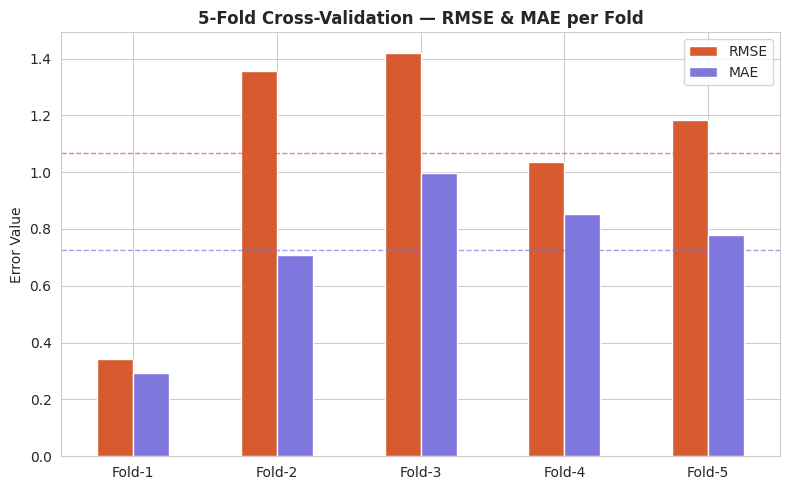


  5. EVALUATION SUMMARY TABLE (Manuscript Format)
Metric  Train Set  Test Set 5-Fold CV (mean±std)
  RMSE     0.0017    1.2671      1.0682 ± 0.4328
    R²     1.0000    0.3775      0.7316 ± 0.1590
   MAE     0.0012    0.8834      0.7261 ± 0.2647

RMSE comparison per country:
       RMSE      R2     MAE
IDN  0.2367  0.7901  0.2001
TWN  1.9162 -0.3422  1.7946


In [33]:
print("\n" + "#" * 70)
print("#  STAGE 2e: MODEL EVALUATION & COMPARATIVE ANALYSIS")
print("#" * 70)

# Full data (train+test) for a more stable K-Fold CV on this small dataset
X_full = pd.concat([X_train, X_test])
y_full = pd.concat([y_train, y_test])

hasil_evaluasi = run_full_evaluation(
    model=model_tuned,
    X_train=X_train, X_test=X_test,
    y_train=y_train, y_test=y_test,
    info_test=info_test,
    model_params=best_params,
    X_full=X_full, y_full=y_full,
    n_splits_cv=5,
    save_dir=OUTPUT_DIR
)

# **CELL 11 — FINAL SUMMARY & EXPORT RESULTS**

In [36]:
print("\n" + "#" * 70)
print("#  FINAL RESEARCH SUMMARY")
print("#" * 70)

print(f"""
Dataset          : {df.shape[0]} observations (16 IDN + 16 TWN), {df.shape[1]} variables
Target           : {TARGET}
Features used    : {len(fitur_final)} features -> {fitur_final}

--- FINAL MODEL PERFORMANCE (after tuning) ---
RMSE (Test)      : {hasil_evaluasi['metrics'].loc['Test', 'RMSE']:.4f}
R²   (Test)      : {hasil_evaluasi['metrics'].loc['Test', 'R2']:.4f}
MAE  (Test)      : {hasil_evaluasi['metrics'].loc['Test', 'MAE']:.4f}

--- CROSS-VALIDATION ({len(hasil_evaluasi['cv_results'])}-FOLD) ---
RMSE (mean±std)  : {hasil_evaluasi['cv_summary'].loc['RMSE','Mean']:.4f} ± {hasil_evaluasi['cv_summary'].loc['RMSE','Std']:.4f}
R²   (mean±std)  : {hasil_evaluasi['cv_summary'].loc['R2','Mean']:.4f} ± {hasil_evaluasi['cv_summary'].loc['R2','Std']:.4f}

--- MOST INFLUENTIAL FEATURES (SHAP) ---
{mean_abs_shap.head(5).to_string(index=False)}

All analysis images & tables are saved to: {OUTPUT_DIR}/
""")

# --- Export final evaluation table to Excel (ready to attach to manuscript) ---
with pd.ExcelWriter(f'{OUTPUT_DIR}/Model_Evaluation_Results.xlsx', engine='openpyxl') as writer:
    hasil_evaluasi['final_table'].to_excel(writer, sheet_name='Evaluation Summary', index=False)
    hasil_evaluasi['compare_country'].to_excel(writer, sheet_name='Comparison IDN vs TWN')
    hasil_evaluasi['eval_detail'].to_excel(writer, sheet_name='Test Set Prediction Details', index=False)
    hasil_evaluasi['cv_results'].to_excel(writer, sheet_name='K-Fold CV Detail')
    mean_abs_shap.to_excel(writer, sheet_name='SHAP Feature Importance', index=False)
    pd.DataFrame({'best_params': pd.Series(best_params)}).to_excel(writer, sheet_name='Best Hyperparameters')

print(f"✓ The complete evaluation results table is saved: {OUTPUT_DIR}/Model_Evaluation_Results.xlsx")

# --- Save final model for reuse (optional) ---
import joblib
joblib.dump(model_tuned, f'{OUTPUT_DIR}/model_xgboost_final.pkl')
print(f"✓ Final model saved: {OUTPUT_DIR}/model_xgboost_final.pkl")

print("\n" + "=" * 70)
print("  RESEARCH PIPELINE COMPLETE")
print("=" * 70)
print(f"SHAP narrative draft for the Discussion section:\n\n{shap_narrative}")


######################################################################
#  FINAL RESEARCH SUMMARY
######################################################################

Dataset          : 32 observations (16 IDN + 16 TWN), 62 variables
Target           : gdp_growth_annual_pct
Features used    : 8 features -> ['eco_efficiency_index', 'co2_yoy_change_pct', 'tourist_arrivals_other', 'domestic_trips_sameday_visitors', 'green_tourism_index', 'tourist_arrivals_water', 'accommodation_occupancy_rate_bedplaces_pct', 'renewable_energy_pct_tfec']

--- FINAL MODEL PERFORMANCE (after tuning) ---
RMSE (Test)      : 1.2671
R²   (Test)      : 0.3775
MAE  (Test)      : 0.8834

--- CROSS-VALIDATION (5-FOLD) ---
RMSE (mean±std)  : 1.0682 ± 0.4328
R²   (mean±std)  : 0.7316 ± 0.1590

--- MOST INFLUENTIAL FEATURES (SHAP) ---
                                   feature  mean_abs_shap
                      eco_efficiency_index       1.576049
           domestic_trips_sameday_visitors       0.622973
          